In [1]:
# --- 1. Clean the Working Directory ---
print("⚙️ Step 1: Cleaning /kaggle/working/ directory...")
import shutil
import os
import sys
working_dir = '/kaggle/working'
if os.path.exists(working_dir):
    for filename in os.listdir(working_dir):
        file_path = os.path.join(working_dir, filename)
        try:
            if os.path.isfile(file_path) or os.path.islink(file_path):
                os.unlink(file_path)
            elif os.path.isdir(file_path):
                shutil.rmtree(file_path)
        except Exception as e:
            print(f'Failed to delete {file_path}. Reason: {e}')
print("✅ Directory cleaned.")

# --- 2. Copy Project Code to Working Directory ---
print("\n⚙️ Step 2: Copying project files...")
!cp -r /kaggle/input/d/datadynamos/402-project/PromptMRG-main /kaggle/working/

# --- 3. Navigate to Project Directory & Set Python Path ---
print("\n⚙️ Step 3: Setting up project directory...")
project_path = '/kaggle/working/PromptMRG-main'
os.chdir(project_path)
sys.path.append(os.path.abspath('.'))
print(f"Current Directory: {os.getcwd()}")

# --- 4. Overwrite medical_dataset.py with the Corrected Version ---
print("\n⚙️ Step 4: Writing corrected medical_dataset.py file...")

# Define the full, correct content for the file as a Python string
corrected_medical_dataset_code = """
import json
import os
import torch
import numpy as np
import random

from torch.utils.data import Dataset

from PIL import Image
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = None

from .utils import my_pre_caption
import os

CONDITIONS = [
    'enlarged cardiomediastinum',
    'cardiomegaly',
    'lung opacity',
    'lung lesion',
    'edema',
    'consolidation',
    'pneumonia',
    'atelectasis',
    'pneumothorax',
    'pleural effusion',
    'pleural other',
    'fracture',
    'support devices',
    'no finding',
]

SCORES = [
'[BLA]',
'[POS]',
'[NEG]',
'[UNC]'
]


class generation_train(Dataset):
    def __init__(self, transform, image_root, ann_root, tokenizer, max_words=100, dataset='mimic_cxr', args=None):
        
        self.annotation = json.load(open(os.path.join(ann_root),'r'))
        self.transform = transform
        self.image_root = image_root
        self.tokenizer = tokenizer
        self.max_words = max_words      
        self.dataset = dataset
        self.args = args

        if dataset == 'mimic_cxr':
            self.ann = self.annotation['train']
        else: # IU-Xray Splitting Logic
            random.seed(args.seed)
            annotation_shuffled = self.annotation[:]
            random.shuffle(annotation_shuffled)
            num_samples = len(annotation_shuffled)
            train_split = int(0.7 * num_samples)
            self.ann = annotation_shuffled[:train_split]

        with open('./data/mimic_cxr/clip_text_features.json', 'r') as f:
            self.clip_features = np.array(json.load(f))
        
    def __len__(self):
        return len(self.ann)
    
    def __getitem__(self, index):    
        
        ann = self.ann[index]
        image_path = ann['image_path']
        image = Image.open(os.path.join(self.image_root, image_path[0])).convert('RGB')
        image = self.transform(image)
        
        cls_labels = ann['labels']
        prompt = [SCORES[l] for l in cls_labels]
        prompt = ' '.join(prompt)+' '
        caption = prompt + my_pre_caption(ann['report'], self.max_words)
        cls_labels = torch.from_numpy(np.array(cls_labels)).long()
        clip_indices = ann['clip_indices'][:self.args.clip_k]
        clip_memory = self.clip_features[clip_indices]
        clip_memory = torch.from_numpy(clip_memory).float()

        return image, caption, cls_labels, clip_memory
    
class generation_eval(Dataset):
    def __init__(self, transform, image_root, ann_root, tokenizer, max_words=100, split='val', dataset='mimic_cxr', args=None):
        self.annotation = json.load(open(os.path.join(ann_root), 'r'))
        self.transform = transform
        self.max_words = max_words
        self.image_root = image_root
        self.tokenizer = tokenizer
        self.dataset = dataset
        self.args = args

        if dataset == 'mimic_cxr':
            self.ann = self.annotation[split]
        else: # IU-Xray Splitting Logic
            random.seed(args.seed)
            annotation_shuffled = self.annotation[:]
            random.shuffle(annotation_shuffled)
            num_samples = len(annotation_shuffled)
            train_split = int(0.7 * num_samples)
            val_split = int(0.85 * num_samples)

            if split == 'val':
                self.ann = annotation_shuffled[train_split:val_split]
            else: # split == 'test'
                self.ann = annotation_shuffled[val_split:]

        with open('./data/mimic_cxr/clip_text_features.json', 'r') as f:
            self.clip_features = np.array(json.load(f))
        
    def __len__(self):
        return len(self.ann)
    
    def __getitem__(self, index):    
        
        ann = self.ann[index]
        image_path = ann['image_path']
        image = Image.open(os.path.join(self.image_root, image_path[0])).convert('RGB')
        image = self.transform(image)

        caption = my_pre_caption(ann['report'], self.max_words)
        cls_labels = ann['labels']
        cls_labels = torch.from_numpy(np.array(cls_labels))
        clip_indices = ann['clip_indices'][:self.args.clip_k]
        clip_memory = self.clip_features[clip_indices]
        clip_memory = torch.from_numpy(clip_memory).float()

        return image, caption, cls_labels, clip_memory
"""

# Use standard Python to write the content to the file
with open('dataset/medical_dataset.py', 'w') as f:
    f.write(corrected_medical_dataset_code)

print("✅ File successfully overwritten.")

# --- 5. Install Dependencies ---
print("\n⚙️ Step 5: Installing dependencies...")
!pip install -r requirements.txt
!pip install rouge_score evaluate bert_score

# --- 6. Prepare Checkpoint Directories ---
print("\n⚙️ Step 6: Preparing checkpoint directories...")
!mkdir -p checkpoints/stanford/chexbert/
!mkdir -p data/mimic_cxr/

# --- 7. Place Pretrained Files (UPDATE THESE PATHS) ---
# ❗ Replace these placeholder paths with your actual file paths from the "Input" pane
chexbert_path = "/kaggle/input/chexpert/chexbert.pth"
clip_features_path = "/kaggle/input/clip-features/clip_text_features.json"
!cp {chexbert_path} ./checkpoints/stanford/chexbert/chexbert.pth
!cp {clip_features_path} ./data/mimic_cxr/clip_text_features.json
print("✅ Setup complete.")

# --- 8. Run Training ---
print("\n🚀 Step 8: Starting training...")
# NOTE: The --ann_path has been corrected to the correct path.
!python main_train.py \
    --image_dir /kaggle/input/iu-xraydataset/iu_xray/images \
    --ann_path /kaggle/input/iu-annotaion/iu_annotation_promptmrg.json \
    --dataset_name iu_xray \
    --threshold 3 \
    --epochs 30 \
    --batch_size 16 \
    --init_lr 5e-5 \
    --save_dir /kaggle/working/results/iu_xray/

⚙️ Step 1: Cleaning /kaggle/working/ directory...
✅ Directory cleaned.

⚙️ Step 2: Copying project files...

⚙️ Step 3: Setting up project directory...
Current Directory: /kaggle/working/PromptMRG-main

⚙️ Step 4: Writing corrected medical_dataset.py file...
✅ File successfully overwritten.

⚙️ Step 5: Installing dependencies...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.9/93.9 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.3/266.3 kB 12.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Reason for being yanked: Version was not properly set
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.8/5.8 MB 75.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00:00:0100:01m
  

⚙️ Step 1: Setting up project directory...
Current Directory: /kaggle/working/PromptMRG-main

⚙️ Step 2: Patching main_test.py for IU-Xray and single-GPU use...
✅ main_test.py patched.

⚙️ Step 3: Patching modules/tester.py for single-GPU use...
✅ modules/tester.py patched.

🚀 Step 4: Starting full evaluation...
2025-07-29 04:22:37.904236: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753762957.927693    1775 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753762957.940026    1775 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
Not using distributed mode
Creating dataset...
number of testing samples: 626
Some weights of the model checkpoint at bert-

2025-07-29 04:28:38.886061: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753763318.909341      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753763318.916288      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Loading model and tokenizer...


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertLMHeadModel: ['bert.embeddings.token_type_embeddings.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertLMHeadModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertLMHeadModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of BertLMHeadModel were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['bert.encoder.layer.3.crossattention.output.dense.weight', 'bert.encoder.layer.10.crossattention.output.LayerNorm.bias', 'bert.encoder.layer.7.crossattention.self.value.weight', 'bert.encoder

✅ Model loaded successfully.

Loading test dataset...
Found 626 samples in the test set.
\n--- Example 1/3 ---


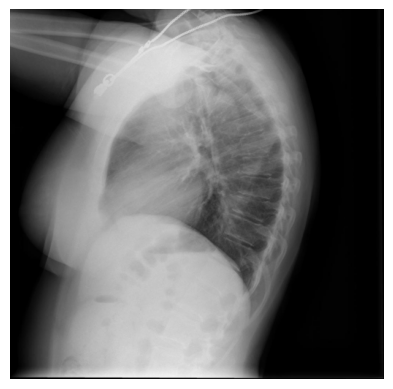

\n✅ Ground Truth Report:
heart size normal . no pneumothorax large pleural effusion or focal airspace disease . bony structures appear intact . calcified right hilar nodules consistent with chronic granulomatous disease .
\n🤖 Generated Report:
the heart pulmonary xxxx and mediastinum are within normal limits. there is no pleural effusion or pneumothorax. there is no focal air space opacity to suggest a pneumonia. the aorta is tortuous and ectatic. there are degenerative changes of the acromioclavicular joints. there degenerative changes of the spine. there is an ivc xxxx identified.
-------------------------
\n--- Example 2/3 ---


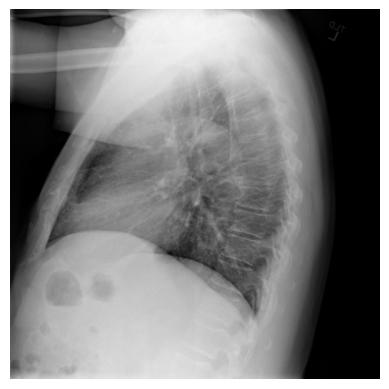

\n✅ Ground Truth Report:
the heart pulmonary xxxx and mediastinum are within normal limits . there is no pleural effusion or pneumothorax . there is no focal air space opacity to suggest a pneumonia . there are minimal degenerative changes of the spine .
\n🤖 Generated Report:
heart size and mediastinal contour are normal. pulmonary vascularity is normal. lungs are clear. no pleural effusions or pneumothoraces. degenerative changes in the thoracic spine.
-------------------------
\n--- Example 3/3 ---


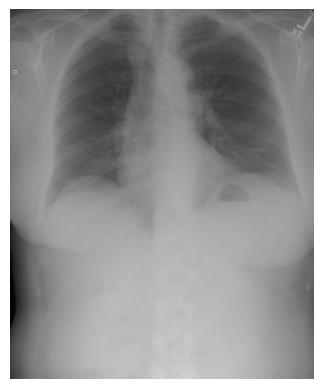

\n✅ Ground Truth Report:
heart size within normal limits . right paratracheal prominence xxxx represents tortuous xxxx . xxxx lung volumes . mild streaky bibasilar opacities . no pleural effusion or pneumothorax .
\n🤖 Generated Report:
the lungs are clear. there is no pleural effusion or pneumothorax. the heart is not significantly enlarged. there are atherosclerotic changes of the aorta. arthritic changes of the skeletal structures are noted.
-------------------------


In [2]:
# --- 1. Navigate to Project Directory & Set Python Path ---
print("⚙️ Step 1: Setting up project directory...")
import os
import sys
project_path = '/kaggle/working/PromptMRG-main'
os.chdir(project_path)
if os.path.abspath('.') not in sys.path:
    sys.path.append(os.path.abspath('.'))
print(f"Current Directory: {os.getcwd()}")

# --- 2. Correct the main_test.py script ---
print("\n⚙️ Step 2: Patching main_test.py for IU-Xray and single-GPU use...")

corrected_main_test_code = """
import os, json
import torch
from torch import nn
import argparse
import numpy as np
from modules.metrics import compute_scores
from modules.tester import Tester
from models.blip import blip_decoder
from dataset import create_dataset
from dataset import create_sampler 
from dataset import create_loader 
from modules import utils
from transformers import BertTokenizer 

import sys
sys.path.append(os.path.abspath('.'))

def parse_agrs():
    parser = argparse.ArgumentParser()
    parser.add_argument('--image_dir', type=str, default='data/iu_xray/images/', help='the path to the directory containing the data.')
    parser.add_argument('--ann_path', type=str, default='data/iu_xray/annotation.json', help='the path to the directory containing the data.')
    parser.add_argument('--image_size', type=int, default=224, help='input image size')
    parser.add_argument('--dataset_name', type=str, default='iu_xray', choices=['iu_xray', 'mimic_cxr'], help='the dataset to be used.')
    parser.add_argument('--threshold', type=int, default=3, help='the cut off frequency for the words.')
    parser.add_argument('--num_workers', type=int, default=2, help='the number of workers for dataloader.')
    parser.add_argument('--batch_size', type=int, default=16, help='the number of samples for a batch')
    parser.add_argument('--load_pretrained', type=str, default=None, help='pretrained path if any')
    parser.add_argument('--beam_size', type=int, default=3, help='the beam size when beam searching.')
    parser.add_argument('--gen_max_len', type=int, default=110, help='the maximum token length for text generation.')
    parser.add_argument('--gen_min_len', type=int, default=60, help='the minimum token length for text generation.')
    parser.add_argument('--n_gpu', type=int, default=1, help='the number of gpus to be used.')
    parser.add_argument('--epochs', type=int, default=10, help='the number of training epochs.')
    parser.add_argument('--save_dir', type=str, default='results/promptmrg', help='the path to save the models.')
    parser.add_argument('--seed', type=int, default=9233, help='.')
    parser.add_argument('--distributed', default=False, type=bool)
    parser.add_argument('--dist_url', default='env://', help='url used to set up distributed training')
    parser.add_argument('--device', default='cuda')
    parser.add_argument('--clip_k', type=int, default=21, help='Number of retrieved reports from database.')
    args = parser.parse_args()
    return args

def main():
    args = parse_agrs()
    utils.init_distributed_mode(args)
    device = torch.device(args.device)
    seed = args.seed + utils.get_rank()
    torch.manual_seed(seed)
    np.random.seed(seed)
    
    tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
    tokenizer.add_special_tokens({'bos_token': '[DEC]'})
    tokenizer.add_tokens(['[BLA]', '[POS]', '[NEG]', '[UNC]'])

    print("Creating dataset...")
    _, _, test_dataset = create_dataset('generation_%s'%args.dataset_name, tokenizer, args)
    print('number of testing samples: %d'%len(test_dataset))
    
    test_dataloader = create_loader([test_dataset], [None], batch_size=[args.batch_size], num_workers=[4], is_trains=[False], collate_fns=[None])[0] 

    num_classes = 14 if args.dataset_name == 'iu_xray' else 18
    labels_temp = ['[BLA]'] * num_classes
    prompt_temp = ' '.join(labels_temp)+' '
    model = blip_decoder(args, tokenizer, image_size=args.image_size, prompt=prompt_temp)
    
    if args.load_pretrained:
        state_dict = torch.load(args.load_pretrained, map_location="cpu")
        model.load_state_dict(state_dict)
        print("load checkpoint from {}".format(args.load_pretrained))

    criterion_cls = nn.CrossEntropyLoss()
    metrics = compute_scores
    model = model.to(device)   

    tester = Tester(model, criterion_cls, metrics, args, device, test_dataloader)
    tester.test_blip()

if __name__ == '__main__':
    main()
"""
with open('main_test.py', 'w') as f:
    f.write(corrected_main_test_code)
print("✅ main_test.py patched.")

# --- 3. Correct the tester.py script ---
print("\n⚙️ Step 3: Patching modules/tester.py for single-GPU use...")
corrected_tester_code = """
import logging
import os
from abc import abstractmethod
import numpy as np
import time
import torch
from .metrics_clinical import CheXbertMetrics

class BaseTester(object):
    def __init__(self, model, criterion_cls, metric_ftns, args, device):
        self.args = args
        self.model = model
        self.device = device
        self.chexbert_metrics = CheXbertMetrics('./checkpoints/stanford/chexbert/chexbert.pth', args.batch_size, device)
        logging.basicConfig(format='%(asctime)s - %(levelname)s - %(name)s -   %(message)s',
                            datefmt='%m/%d/%Y %H:%M:%S', level=logging.INFO)
        self.logger = logging.getLogger(__name__)
        self.criterion_cls = criterion_cls
        self.metric_ftns = metric_ftns
        self.epochs = args.epochs
        self.save_dir = args.save_dir

class Tester(BaseTester):
    def __init__(self, model, criterion_cls, metric_ftns, args, device, test_dataloader):
        super(Tester, self).__init__(model, criterion_cls, metric_ftns, args, device)
        self.test_dataloader = test_dataloader

    def test_blip(self):
        self.logger.info('Start to evaluate in the test set.')
        log = dict()
        model_to_eval = self.model
        model_to_eval.eval()
        with torch.no_grad():
            test_gts, test_res = [], []
            for batch_idx, (images, captions, cls_labels, clip_memory) in enumerate(self.test_dataloader):
                images = images.to(self.device) 
                clip_memory = clip_memory.to(self.device) 
                ground_truths = captions
                reports, _, _ = model_to_eval.generate(images, clip_memory, sample=False, num_beams=self.args.beam_size, max_length=self.args.gen_max_len, min_length=self.args.gen_min_len)

                test_res.extend(reports)
                test_gts.extend(ground_truths)
                if batch_idx % 10 == 0:
                    print('{}/{}'.format(batch_idx, len(self.test_dataloader)))
            
            test_met = self.metric_ftns({i: [gt] for i, gt in enumerate(test_gts)},
                                        {i: [re] for i, re in enumerate(test_res)})
            test_ce = self.chexbert_metrics.compute(test_gts, test_res)
            
            log.update(**{'test_' + k: v for k, v in test_met.items()})
            log.update(**{'test_' + k: v for k, v in test_ce.items()})
            
            print("\\n--- Test Set Evaluation Results ---")
            for key, value in log.items():
                print(f'{key}: {value:.4f}')
        return log
"""
with open('modules/tester.py', 'w') as f:
    f.write(corrected_tester_code)
print("✅ modules/tester.py patched.")

# --- 4. Run the Full Test Evaluation ---
print("\n🚀 Step 4: Starting full evaluation...")
!python main_test.py \
    --image_dir /kaggle/input/iu-xraydataset/iu_xray/images \
    --ann_path /kaggle/input/iu-annotaion/iu_annotation_promptmrg.json \
    --dataset_name iu_xray \
    --threshold 3 \
    --load /kaggle/working/results/iu_xray/model_best.pth \
    --beam_size 3

# --- 5. Visualize Generated Examples ---
print("\n🖼️ Step 5: Generating and displaying examples...")
import torch
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from transformers import BertTokenizer
from models.blip import blip_decoder
from dataset import create_dataset

# --- Configuration ---
class Args:
    def __init__(self):
        self.image_dir = '/kaggle/input/iu-xraydataset/iu_xray/images'
        self.ann_path = '/kaggle/input/iu-annotaion/iu_annotation_promptmrg.json'
        self.dataset_name = 'iu_xray'
        self.image_size = 224
        self.threshold = 3
        self.seed = 9233
        self.clip_k = 21
        self.beam_size = 3
        self.gen_max_len = 110
        self.gen_min_len = 60

args = Args()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- Load Model and Tokenizer ---
print("Loading model and tokenizer...")
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
tokenizer.add_special_tokens({'bos_token': '[DEC]'})
tokenizer.add_tokens(['[BLA]', '[POS]', '[NEG]', '[UNC]'])

num_classes = 14
labels_temp = ['[BLA]'] * num_classes
prompt_temp = ' '.join(labels_temp)+' '
model = blip_decoder(args, tokenizer, image_size=args.image_size, prompt=prompt_temp)

model_path = '/kaggle/working/results/iu_xray/model_best.pth'
state_dict = torch.load(model_path, map_location="cpu")
model.load_state_dict(state_dict)
model = model.to(device)
model.eval()
print("✅ Model loaded successfully.")

# --- Load Test Dataset ---
print("\nLoading test dataset...")
_, _, test_dataset = create_dataset('generation_iu_xray', tokenizer, args)
print(f"Found {len(test_dataset)} samples in the test set.")

# --- Generate and Display Examples ---
num_examples_to_show = 3
random_indices = random.sample(range(len(test_dataset)), num_examples_to_show)

for i, idx in enumerate(random_indices):
    image_tensor, ground_truth_caption, _, clip_memory = test_dataset[idx]
    
    raw_image_path = os.path.join(args.image_dir, test_dataset.ann[idx]['image_path'][0])
    raw_image = Image.open(raw_image_path).convert('RGB')
    
    with torch.no_grad():
        generated_captions, _, _ = model.generate(image_tensor.unsqueeze(0).to(device), 
                                                  clip_memory.unsqueeze(0).to(device), 
                                                  sample=False, 
                                                  num_beams=args.beam_size, 
                                                  max_length=args.gen_max_len, 
                                                  min_length=args.gen_min_len)
    generated_report = generated_captions[0]

    # Display results
    print(f"\\n--- Example {i+1}/{num_examples_to_show} ---")
    plt.imshow(raw_image)
    plt.axis('off')
    plt.show()
    
    print("\\n✅ Ground Truth Report:")
    print(ground_truth_caption)
    
    print("\\n🤖 Generated Report:")
    print(generated_report)
    print("-" * 25)